In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
os.listdir('/content/drive/MyDrive/5G_IDS_Project/')

['data', 'notebooks', 'models']

In [ ]:
data_folder_path = '/content/drive/MyDrive/5G_IDS_Project/data/'
print(os.listdir(data_folder_path))

['raw', 'cleaned']


In [ ]:
import pandas as pd

# file training path
csv_file_path = '/content/drive/MyDrive/5G_IDS_Project/data/raw/CSV Files/Training and Testing Sets/UNSW_NB15_training-set.csv'
df = pd.read_csv(csv_file_path)
display(df.head())

,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,...,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,...,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,...,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,...,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,...,1,40,0,0,0,2,39,0,Normal,0


In [ ]:
df = pd.read_csv(csv_file_path, skipinitialspace=True, low_memory=False, encoding='utf-8')

In [ ]:
df.drop(columns=['id'], inplace=True)

In [ ]:
df.dtypes
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 175341 entries, 0 to 175340
Data columns (total 44 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   dur                175341 non-null  float64
 1   proto              175341 non-null  object 
 2   service            175341 non-null  object 
 3   state              175341 non-null  object 
 4   spkts              175341 non-null  int64  
 5   dpkts              175341 non-null  int64  
 6   sbytes             175341 non-null  int64  
 7   dbytes             175341 non-null  int64  
 8   rate               175341 non-null  float64
 9   sttl               175341 non-null  int64  
 10  dttl               175341 non-null  int64  
 11  sload              175341 non-null  float64
 12  dload              175341 non-null  float64
 13  sloss              175341 non-null  int64  
 14  dloss              175341 non-null  int64  
 15  sinpkt             175341 non-null  float64
 16  di

In [ ]:
from fastai.tabular.all import df_shrink

In [ ]:
df = df_shrink(df, skip=[], obj2cat=True, int2uint=False)

In [ ]:
df.isna().sum()

,0
dur,0
proto,0
service,0
state,0
spkts,0
dpkts,0
sbytes,0
dbytes,0
rate,0
sttl,0


In [ ]:
# Đường dẫn lưu file đã làm sạch vào thư mục cleaned
cleaned_path = '/content/drive/MyDrive/5G_IDS_Project/data/cleaned/UNSW_NB15_training-set.parquet'

# Lưu DataFrame df thành file Parquet
df.to_parquet(cleaned_path)
print("Đã lưu file Parquet thành công tại:", cleaned_path)

Đã lưu file Parquet thành công tại: /content/drive/MyDrive/5G_IDS_Project/data/cleaned/UNSW_NB15_training-set.parquet


In [ ]:
df.info()
df.head(10)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 175341 entries, 0 to 175340
Data columns (total 44 columns):
 #   Column             Non-Null Count   Dtype   
---  ------             --------------   -----   
 0   dur                175341 non-null  float32 
 1   proto              175341 non-null  category
 2   service            175341 non-null  category
 3   state              175341 non-null  category
 4   spkts              175341 non-null  int16   
 5   dpkts              175341 non-null  int16   
 6   sbytes             175341 non-null  int32   
 7   dbytes             175341 non-null  int32   
 8   rate               175341 non-null  float32 
 9   sttl               175341 non-null  int16   
 10  dttl               175341 non-null  int16   
 11  sload              175341 non-null  float32 
 12  dload              175341 non-null  float32 
 13  sloss              175341 non-null  int16   
 14  dloss              175341 non-null  int16   
 15  sinpkt             175341 non-null

,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sttl,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,0.121478,tcp,-,FIN,6,4,258,172,74.087486,252,...,1,1,0,0,0,1,1,0,Normal,0
1,0.649902,tcp,-,FIN,14,38,734,42014,78.473373,62,...,1,2,0,0,0,1,6,0,Normal,0
2,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,62,...,1,3,0,0,0,2,6,0,Normal,0
3,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,62,...,1,3,1,1,0,2,1,0,Normal,0
4,0.449454,tcp,-,FIN,10,6,534,268,33.373825,254,...,1,40,0,0,0,2,39,0,Normal,0
5,0.380537,tcp,-,FIN,10,6,534,268,39.417980,254,...,1,40,0,0,0,2,39,0,Normal,0
6,0.637109,tcp,-,FIN,10,8,534,354,26.683033,254,...,1,40,0,0,0,1,39,0,Normal,0
7,0.521584,tcp,-,FIN,10,8,534,354,32.593025,254,...,1,40,0,0,0,3,39,0,Normal,0
8,0.542905,tcp,-,FIN,10,8,534,354,31.313030,254,...,1,40,0,0,0,3,39,0,Normal,0
9,0.258687,tcp,-,FIN,10,6,534,268,57.985134,254,...,1,40,0,0,0,3,39,0,Normal,0


In [ ]:
import pandas as pd

# Load lại file parquet đã lưu ở Tuần 2
cleaned_path = '/content/drive/MyDrive/5G_IDS_Project/data/cleaned/UNSW_NB15_training-set.parquet'
df = pd.read_parquet(cleaned_path)

# Loại bỏ các cột ô nhiễm
contaminating_cols = ['sttl', 'dttl', 'ct_state_ttl']
useless_cols = ['is_sm_ips_ports', 'ct_ftp_cmd', 'is_ftp_login']
cols_to_drop = ['id'] + contaminating_cols + useless_cols

df.drop(columns=cols_to_drop, errors='ignore', inplace=True)

print(f"Tổng số cột còn lại: {len(df.columns)}")
print("Danh sách các cột:")
print(df.columns.tolist())
display(df.head())

Tổng số cột còn lại: 38
Danh sách các cột:
['dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'attack_cat', 'label']


,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sload,...,ct_srv_src,ct_dst_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,attack_cat,label
0,0.121478,tcp,-,FIN,6,4,258,172,74.087486,14158.942383,...,1,1,1,1,1,0,1,1,Normal,0
1,0.649902,tcp,-,FIN,14,38,734,42014,78.473373,8395.112305,...,43,1,1,1,2,0,1,6,Normal,0
2,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,1572.271851,...,7,2,1,1,3,0,2,6,Normal,0
3,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,2740.178955,...,1,2,1,1,3,0,2,1,Normal,0
4,0.449454,tcp,-,FIN,10,6,534,268,33.373825,8561.499023,...,43,2,2,1,40,0,2,39,Normal,0


Bảng thống kê số lượng luồng mạng (Normal vs Attack):


,Số lượng
label,
1,119341
0,56000


/tmp/ipykernel_2905/516970366.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x='label', data=df, palette='Set2')


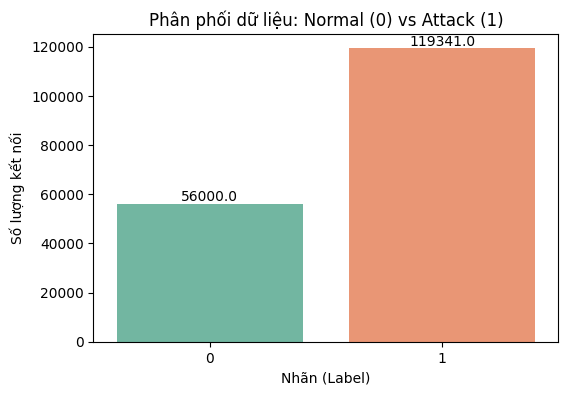

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Xuất bảng thống kê số lượng chính xác
print("Bảng thống kê số lượng luồng mạng (Normal vs Attack):")
display(df['label'].value_counts().to_frame(name='Số lượng'))

# Xuất biểu đồ trực quan
plt.figure(figsize=(6, 4))
ax = sns.countplot(x='label', data=df, palette='Set2')
plt.title('Phân phối dữ liệu: Normal (0) vs Attack (1)')
plt.xlabel('Nhãn (Label)')
plt.ylabel('Số lượng kết nối')

for p in ax.patches:
    ax.annotate(f'{p.get_height()}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=10, color='black')
plt.show()

In [ ]:
from sklearn.preprocessing import LabelEncoder

# Tách Target (y) và Features (X)
y = df['label']
X = df.drop(columns=['label', 'attack_cat'], errors='ignore')

print("Kiểm tra cột phân loại ban đầu:")
categorical_cols = X.select_dtypes(include=['category', 'object']).columns
le = LabelEncoder()
display(X[categorical_cols].head())

for col in categorical_cols:
    X[col] = le.fit_transform(X[col].astype(str))

print("Kiểm tra các cột phân loại (proto, service, state) đã chuyển thành số:")
display(X[categorical_cols].head())

Kiểm tra cột phân loại ban đầu:


,proto,service,state
0,tcp,-,FIN
1,tcp,-,FIN
2,tcp,-,FIN
3,tcp,ftp,FIN
4,tcp,-,FIN


Kiểm tra các cột phân loại (proto, service, state) đã chuyển thành số:


,proto,service,state
0,113,0,2
1,113,0,2
2,113,0,2
3,113,3,2
4,113,0,2


In [ ]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)

print("Ma trận dữ liệu sau khi chuẩn hóa tỷ lệ:")
display(X_scaled.head())

print("\nKiểm tra dải giá trị chốt hạ của các đặc trưng")
display(X_scaled.describe().loc[['min', 'max']])

Ma trận dữ liệu sau khi chuẩn hóa tỷ lệ:


,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sload,...,trans_depth,response_body_len,ct_srv_src,ct_dst_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst
0,0.002025,0.856061,0.00,0.25,0.000520,0.000364,0.000018,0.000012,0.000074,2.364553e-06,...,0.0,0.0,0.000000,0.00,0.00,0.0,0.000000,0.0,0.000000,0.000000
1,0.010832,0.856061,0.00,0.25,0.001352,0.003463,0.000054,0.002867,0.000078,1.401989e-06,...,0.0,0.0,0.677419,0.00,0.00,0.0,0.015625,0.0,0.000000,0.081967
2,0.027052,0.856061,0.00,0.25,0.000728,0.001458,0.000026,0.000900,0.000014,2.625704e-07,...,0.0,0.0,0.096774,0.02,0.00,0.0,0.031250,0.0,0.016949,0.081967
3,0.028027,0.856061,0.25,0.25,0.001144,0.001093,0.000046,0.000053,0.000014,4.576117e-07,...,0.0,0.0,0.000000,0.02,0.00,0.0,0.031250,0.0,0.016949,0.000000
4,0.007491,0.856061,0.00,0.25,0.000936,0.000547,0.000039,0.000018,0.000033,1.429776e-06,...,0.0,0.0,0.677419,0.02,0.02,0.0,0.609375,0.0,0.016949,0.622951



Kiểm tra dải giá trị chốt hạ của các đặc trưng


,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sload,...,trans_depth,response_body_len,ct_srv_src,ct_dst_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst
min,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
max,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [ ]:
display(df.head())

,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sload,...,ct_srv_src,ct_dst_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,attack_cat,label
0,0.121478,tcp,-,FIN,6,4,258,172,74.087486,14158.942383,...,1,1,1,1,1,0,1,1,Normal,0
1,0.649902,tcp,-,FIN,14,38,734,42014,78.473373,8395.112305,...,43,1,1,1,2,0,1,6,Normal,0
2,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,1572.271851,...,7,2,1,1,3,0,2,6,Normal,0
3,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,2740.178955,...,1,2,1,1,3,0,2,1,Normal,0
4,0.449454,tcp,-,FIN,10,6,534,268,33.373825,8561.499023,...,43,2,2,1,40,0,2,39,Normal,0
